### 1. Ortam Bağımsız Klasör Yapısı

Bu kod bloğu sayesinde eğitimleri Google Colab'da yapıp tahminleme ve değerlendirme adımlarını lokalde yapabileceğimiz dinamik bir klasör yapısı sağlanır.

In [ ]:
import os
import json
import random
from collections import defaultdict
from pathlib import Path
from PIL import Image, ImageOps

# Ortamı otomatik algıla
IN_COLAB = "COLAB_GPU" in os.environ or os.path.exists("/content")

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/training_data/quadrant_enumeration")
else:

    BASE_DIR = Path("./training_data/quadrant_enumeration").resolve()

JSON_PATH = BASE_DIR / "train_quadrant_enumeration.json"
IMAGES_DIR = BASE_DIR / "xrays"
OUTPUT_DIR = BASE_DIR / "datasets" / "single_model_hemisection"

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
SEED = 42
OVERLAP_RATIO = 0.05

for split in ["train", "val", "test"]:
    (OUTPUT_DIR / "images" / split).mkdir(parents=True, exist_ok=True)
    (OUTPUT_DIR / "labels" / split).mkdir(parents=True, exist_ok=True)

print("Aktif Çalışma Dizini:", BASE_DIR)
print("JSON Dosyası Mevcut mu?:", JSON_PATH.exists())
print("Görsel Klasörü Mevcut mu?:", IMAGES_DIR.exists())

Mounted at /content/drive
Aktif Çalışma Dizini: /content/drive/MyDrive/training_data/quadrant_enumeration
JSON Dosyası Mevcut mu?: True
Görsel Klasörü Mevcut mu?: True


### 2. COCO JSON Formatından YOLO Formatına Geçiş

In [ ]:
def clamp(val, min_val, max_val):
    return max(min_val, min(val, max_val))

def to_yolo_bbox(x_min, y_min, x_max, y_max, img_w, img_h):
    bw = (x_max - x_min) / img_w
    bh = (y_max - y_min) / img_h
    xc = (x_min + (x_max - x_min) / 2.0) / img_w
    yc = (y_min + (y_max - y_min) / 2.0) / img_h
    return (
        clamp(xc, 0.0, 1.0),
        clamp(yc, 0.0, 1.0),
        clamp(bw, 0.0, 1.0),
        clamp(bh, 0.0, 1.0),
    )

def map_to_16_classes(quadrant_id: int, tooth_id: int) -> int:
    if quadrant_id in (0, 1):
        return tooth_id
    return 8 + tooth_id

random.seed(SEED)

with open(JSON_PATH, "r", encoding="utf-8") as f:
    coco = json.load(f)

images_info = {img["id"]: img for img in coco["images"]}
anns_by_image = defaultdict(list)
for ann in coco["annotations"]:
    anns_by_image[ann["image_id"]].append(ann)

all_image_ids = list(images_info.keys())
random.shuffle(all_image_ids)

total = len(all_image_ids)
train_end = int(total * TRAIN_RATIO)
val_end = train_end + int(total * VAL_RATIO)

train_ids = set(all_image_ids[:train_end])
val_ids = set(all_image_ids[train_end:val_end])
test_ids = set(all_image_ids[val_end:])

def get_split(img_id: int) -> str:
    if img_id in train_ids:
        return "train"
    elif img_id in val_ids:
        return "val"
    return "test"

print(f"Toplam: {total} | Train: {len(train_ids)} | Val: {len(val_ids)} | Test: {len(test_ids)}")

Toplam: 634 | Train: 443 | Val: 95 | Test: 96


### 3. Dönüştürme Döngüsü

In [ ]:
from tqdm.notebook import tqdm

processed_count = 0
skipped_count = 0

for img_id, img_meta in tqdm(list(images_info.items()), desc="Görseller İşleniyor"):
    file_name = img_meta["file_name"]
    src_img_path = IMAGES_DIR / file_name
    if not src_img_path.exists():
        continue

    split = get_split(img_id)
    stem = Path(file_name).stem

    # Dosya yolları
    r_img_path = OUTPUT_DIR / "images" / split / f"{stem}_R.png"
    l_img_path = OUTPUT_DIR / "images" / split / f"{stem}_L_flip.png"

    # Eğer bu görsel daha önce işlenip kaydedildiyse pas geç (Hız kazanmak için resume özelliği)
    if r_img_path.exists() and l_img_path.exists():
        skipped_count += 1
        processed_count += 1
        continue

    img_w, img_h = img_meta["width"], img_meta["height"]
    anns = anns_by_image.get(img_id, [])
    if not anns:
        continue

    mid_x = img_w / 2.0
    overlap_px = img_w * OVERLAP_RATIO

    with Image.open(src_img_path) as pil_img:
        # 1. PARÇA: Sol Yarı (Hastanın Sağ Çenesi)
        right_crop_x2 = int(clamp(mid_x + overlap_px, 0, img_w))
        right_w = right_crop_x2

        right_img = pil_img.crop((0, 0, right_crop_x2, img_h))
        right_img.save(r_img_path)

        r_labels = []
        for a in anns:
            tx1, ty1, tw, th = a["bbox"]
            tx2, ty2 = tx1 + tw, ty1 + th
            nx1, nx2 = clamp(tx1, 0, right_w), clamp(tx2, 0, right_w)
            if (nx2 - nx1) >= (tw * 0.50):
                cls_id = map_to_16_classes(a["category_id_1"], a["category_id_2"])
                xc, yc, bw, bh = to_yolo_bbox(nx1, ty1, nx2, ty2, right_w, img_h)
                r_labels.append(f"{cls_id} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}")

        (OUTPUT_DIR / "labels" / split / f"{stem}_R.txt").write_text("\n".join(r_labels), encoding="utf-8")

        # 2. PARÇA: Sağ Yarı (Hastanın Sol Çenesi) -> Yatay Aynalama
        left_crop_x1 = int(clamp(mid_x - overlap_px, 0, img_w))
        left_w = img_w - left_crop_x1

        left_img = pil_img.crop((left_crop_x1, 0, img_w, img_h))
        left_img_flipped = ImageOps.mirror(left_img)
        left_img_flipped.save(l_img_path)

        l_labels = []
        for a in anns:
            tx1, ty1, tw, th = a["bbox"]
            tx2, ty2 = tx1 + tw, ty1 + th
            nx1, nx2 = clamp(tx1 - left_crop_x1, 0, left_w), clamp(tx2 - left_crop_x1, 0, left_w)
            if (nx2 - nx1) >= (tw * 0.50):
                fx1, fx2 = left_w - nx2, left_w - nx1
                cls_id = map_to_16_classes(a["category_id_1"], a["category_id_2"])
                xc, yc, bw, bh = to_yolo_bbox(fx1, ty1, fx2, ty2, left_w, img_h)
                l_labels.append(f"{cls_id} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}")

        (OUTPUT_DIR / "labels" / split / f"{stem}_L_flip.txt").write_text("\n".join(l_labels), encoding="utf-8")

    processed_count += 1

print(f"Tamamlandı! {skipped_count} görsel zaten hazırdı, atlandı.")
print(f"Toplam {processed_count * 2} yarım-çene görseli (70/15/15) diskte güncel durumda.")

Görseller İşleniyor:   0%|          | 0/634 [00:00<?, ?it/s]

Tamamlandı! 330 görsel zaten hazırdı, atlandı.
Toplam 1268 yarım-çene görseli (70/15/15) diskte güncel durumda.


### 4. YAML Oluşturma ve Görsel Kontrol

data.yaml başarıyla oluşturuldu: /content/drive/MyDrive/training_data/quadrant_enumeration/datasets/single_model_hemisection/data.yaml


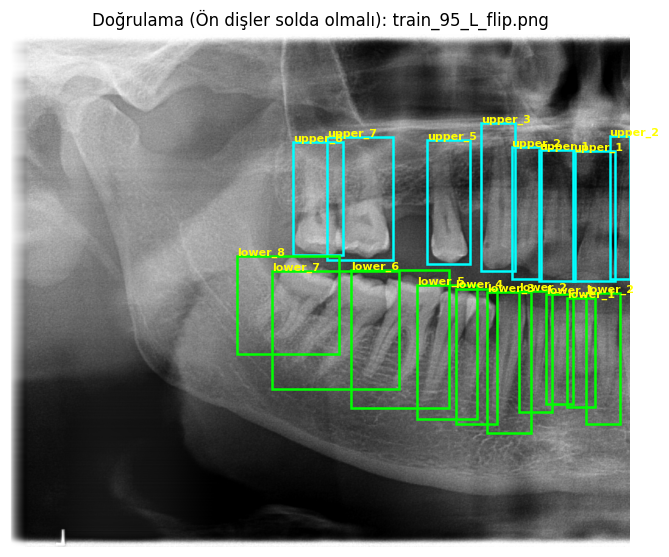

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

class_names = [f"upper_{i+1}" for i in range(8)] + [f"lower_{i+1}" for i in range(8)]
yaml_content = (
    f"path: {OUTPUT_DIR.as_posix()}\n"
    f"train: images/train\n"
    f"val: images/val\n"
    f"test: images/test\n"
    f"nc: 16\n"
    f"names: {class_names}\n"
)
(OUTPUT_DIR / "data.yaml").write_text(yaml_content, encoding="utf-8")
print("data.yaml başarıyla oluşturuldu:", OUTPUT_DIR / "data.yaml")

# Görsel Doğrulama (Aynalanmış bir örnek)
sample_img_path = next((OUTPUT_DIR / "images" / "train").glob("*_L_flip.png"))
sample_lbl_path = OUTPUT_DIR / "labels" / "train" / f"{sample_img_path.stem}.txt"

img = Image.open(sample_img_path)
w, h = img.size

fig, ax = plt.subplots(1, figsize=(8, 8))
ax.imshow(img)

for line in sample_lbl_path.read_text().splitlines():
    cls_id, xc, yc, bw, bh = map(float, line.split())
    cls_id = int(cls_id)
    x1 = (xc - bw / 2) * w
    y1 = (yc - bh / 2) * h
    color = "cyan" if cls_id < 8 else "lime"
    rect = patches.Rectangle((x1, y1), bw * w, bh * h, linewidth=1.8, edgecolor=color, facecolor="none")
    ax.add_patch(rect)
    ax.text(x1, y1 - 3, class_names[cls_id], color="yellow", fontsize=8, fontweight="bold")

plt.title(f"Doğrulama: {sample_img_path.name}")
plt.axis("off")
plt.show()

### 5. Model Eğitimi

### 5.1. Verileri Hızlı Eğitim için Colab Lokaline Taşıma
Google Drive üzerinden eğitim yapmak RAM taşmasına ve yavaşlığa sebep olur. Veriyi lokal `/content` dizinine kopyalayıp yeni bir YAML dosyası oluşturalım.

In [ ]:
import shutil
from pathlib import Path

# Hedef lokal dizin
LOCAL_DATA_DIR = Path("/content/dataset_local")

# Eğer zaten kopyalanmadıysa hızlıca kopyala
if not LOCAL_DATA_DIR.exists():
    print("Veriler Google Drive'dan lokal disk alanına kopyalanıyor...")
    shutil.copytree(str(OUTPUT_DIR), str(LOCAL_DATA_DIR))
    print("Kopyalama tamamlandı!")
else:
    print("Veriler zaten lokal alanda mevcut.")

class_names = [f"upper_{i+1}" for i in range(8)] + [f"lower_{i+1}" for i in range(8)]

# Lokal alan için yeni data.yaml oluştur
local_yaml_content = (
    f"path: {LOCAL_DATA_DIR.as_posix()}\n"
    f"train: images/train\n"
    f"val: images/val\n"
    f"test: images/test\n"
    f"nc: 16\n"
    f"names: {class_names}\n"
)
LOCAL_YAML_PATH = LOCAL_DATA_DIR / "data_local.yaml"
LOCAL_YAML_PATH.write_text(local_yaml_content, encoding="utf-8")
print("Lokal YAML dosyası oluşturuldu:", LOCAL_YAML_PATH)

Veriler zaten lokal alanda mevcut.
Lokal YAML dosyası oluşturuldu: /content/dataset_local/data_local.yaml


In [ ]:
from PIL import Image
from tqdm.notebook import tqdm

all_imgs = list(LOCAL_DATA_DIR.rglob("*.png"))
print(f"Küçültülecek görsel sayısı: {len(all_imgs)}")

for img_path in tqdm(all_imgs, desc="Görseller Optimize Ediliyor"):
    with Image.open(img_path) as im:
        if max(im.size) > 800:
            im.thumbnail((800, 800), Image.Resampling.LANCZOS)
            im.save(img_path, optimize=True)

Küçültülecek görsel sayısı: 1268


Görseller Optimize Ediliyor:   0%|          | 0/1268 [00:00<?, ?it/s]

### 5.2. Model Eğitimi (YOLOv8s)

In [ ]:
!pip install -q ultralytics

import torch
from ultralytics import YOLO

print("CUDA (GPU) Aktif mi?:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Kullanılan GPU:", torch.cuda.get_device_name(0))

model = YOLO("yolov8s.pt")

results = model.train(
    data=str(LOCAL_YAML_PATH),
    epochs=20,
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    cache="disk",        # RAM'e değil lokal SSD'ye önbellekle
    fliplr=0.0,
    project=str(BASE_DIR / "runs"),
    name="hemisection_yolov8s_fast",
    patience=15
)

CUDA (GPU) Aktif mi?: True
Kullanılan GPU: Tesla T4
Ultralytics 8.4.217 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_local/data_local.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, nam

In [ ]:
best_model_path = BASE_DIR / "runs" / "hemisection_yolov8s_fast" / "weights" / "best.pt"
best_model = YOLO(str(best_model_path))

test_metrics = best_model.val(
    data=str(OUTPUT_DIR / "data.yaml"),
    split="test",
    project=str(BASE_DIR / "runs"),
    name="hemisection_test_eval"
)

print(f"Test mAP50: {test_metrics.box.map50:.4f}")
print(f"Test mAP50-95: {test_metrics.box.map:.4f}")

Ultralytics 8.4.217 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,131,776 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 4.8±9.6 ms, read: 123.0±86.1 MB/s, size: 1129.2 KB)
val: Scanning /content/drive/MyDrive/training_data/quadrant_enumeration/datasets/single_model_hemisection/labels/test... 192 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 192/192 92.9it/s 2.1s
val: New cache created: /content/drive/MyDrive/training_data/quadrant_enumeration/datasets/single_model_hemisection/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 12/12 1.0s/it 12.5s
                   all        192       3501      0.927      0.935      0.953      0.537
               upper_1        190        373      0.976      0.979      0.988      0.548
               upper_2        188        320      0.934      0.922       0.95      0.504
               upper_3

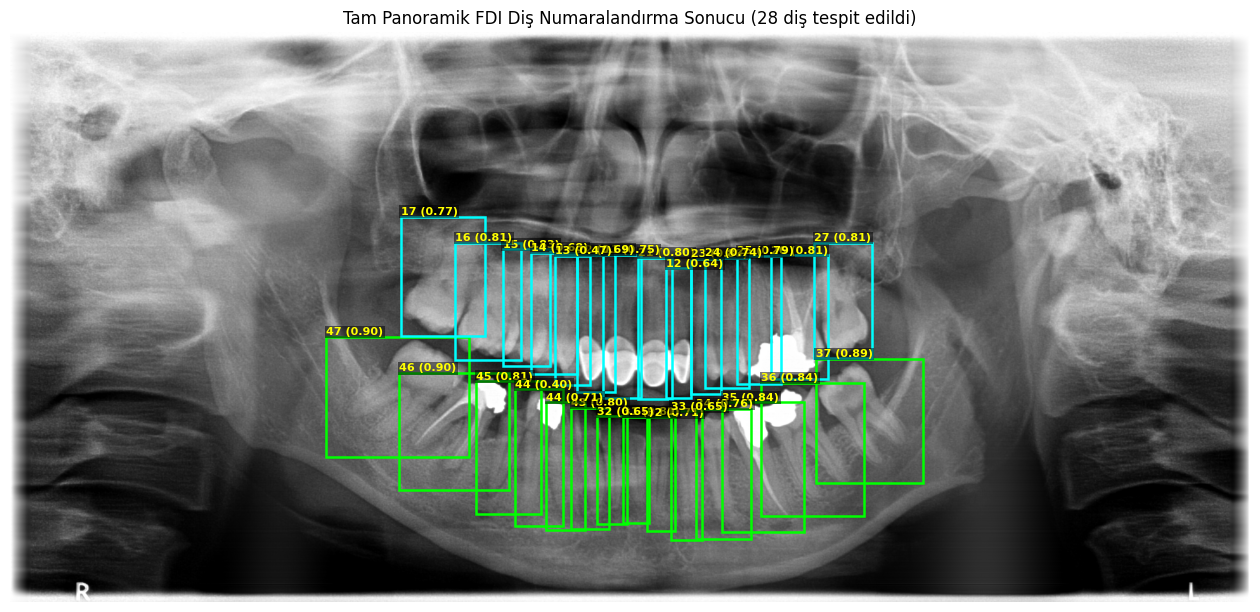

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
from PIL import Image, ImageOps
from ultralytics import YOLO

# Eğitilen en iyi modelin yolu
BEST_WEIGHTS = BASE_DIR / "runs" / "hemisection_yolov8s_fast" / "weights" / "best.pt"
model = YOLO(str(BEST_WEIGHTS))

OVERLAP_RATIO = 0.05  # Eğitimde kullandığımız %5 merkez taşma payı


def class_to_fdi(cls_id: int, side: str) -> str:
    """
    Modelin 0..15 sınıf çıktısını standart FDI diş numarasına (11-48) çevirir.
    side == 'R' -> Görüntünün sol yarısı (Hastanın SAĞ çenesi: Kadran 1 ve 4)
    side == 'L' -> Görüntünün sağ yarısı (Hastanın SOL çenesi: Kadran 2 ve 3)
    """
    is_upper = cls_id < 8
    tooth_num = (cls_id % 8) + 1  # 1..8 arası diş sırası

    if side == "R":
        quadrant = 1 if is_upper else 4
    else:
        quadrant = 2 if is_upper else 3

    return f"{quadrant}{tooth_num}"


def compute_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    inter = max(0.0, x2 - x1) * max(0.0, y2 - y1)
    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    union = area1 + area2 - inter
    return inter / union if union > 0 else 0.0


def predict_full_panoramic(image_path: Path, conf_thres: float = 0.35, iou_thres: float = 0.50):
    pil_img = Image.open(image_path).convert("RGB")
    img_w, img_h = pil_img.size
    mid_x = img_w / 2.0
    overlap_px = img_w * OVERLAP_RATIO

    # 1. PARÇA: Görüntünün Sol Yarısı (Hastanın Sağ Çenesi)
    right_crop_x2 = int(min(img_w, mid_x + overlap_px))
    right_img = pil_img.crop((0, 0, right_crop_x2, img_h))

    # 2. PARÇA: Görüntünün Sağ Yarısı (Hastanın Sol Çenesi) -> Aynala
    left_crop_x1 = int(max(0, mid_x - overlap_px))
    left_w = img_w - left_crop_x1
    left_img = pil_img.crop((left_crop_x1, 0, img_w, img_h))
    left_img_flipped = ImageOps.mirror(left_img)

    # Her iki yarı için modelden tahmin al
    res_r = model.predict(right_img, conf=conf_thres, verbose=False)[0]
    res_l = model.predict(left_img_flipped, conf=conf_thres, verbose=False)[0]

    raw_detections = []

    # Sağ çene tahminlerini orijinal koordinatlara aktar
    for box in res_r.boxes:
        x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()
        cls_id = int(box.cls[0].item())
        conf = float(box.conf[0].item())
        fdi = class_to_fdi(cls_id, side="R")
        raw_detections.append({
            "bbox": [float(x1), float(y1), float(x2), float(y2)],
            "fdi": fdi,
            "conf": conf,
            "is_upper": cls_id < 8
        })

    # Sol çene tahminlerinin aynasını geri çevirip orijinal koordinatlara oturt
    for box in res_l.boxes:
        fx1, y1, fx2, y2 = box.xyxy[0].cpu().numpy()
        cls_id = int(box.cls[0].item())
        conf = float(box.conf[0].item())

        # Yatay aynayı tersine çevir ve left_crop_x1 ofsetini ekle
        orig_x1 = (left_w - fx2) + left_crop_x1
        orig_x2 = (left_w - fx1) + left_crop_x1
        fdi = class_to_fdi(cls_id, side="L")
        raw_detections.append({
            "bbox": [float(orig_x1), float(y1), float(orig_x2), float(y2)],
            "fdi": fdi,
            "conf": conf,
            "is_upper": cls_id < 8
        })

    # Merkez taşma bölgesindeki çift tespitleri (IoU > 0.50) güven skoruna göre ele
    raw_detections.sort(key=lambda d: d["conf"], reverse=True)
    final_detections = []
    for det in raw_detections:
        if all(compute_iou(det["bbox"], kept["bbox"]) < iou_thres for kept in final_detections):
            final_detections.append(det)

    return pil_img, final_detections


# --- ÖRNEK TEST GÖRSELİ ÜZERİNDE ÇALIŞTIR VE GÖRSELLEŞTİR ---
sample_raw_xray = next(IMAGES_DIR.glob("*.png"))  # Veya test setinden bir görsel yolu verin
full_img, detections = predict_full_panoramic(sample_raw_xray, conf_thres=0.35)

fig, ax = plt.subplots(1, figsize=(16, 8))
ax.imshow(full_img)

for det in detections:
    x1, y1, x2, y2 = det["bbox"]
    color = "cyan" if det["is_upper"] else "lime"
    rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=1.8, edgecolor=color, facecolor="none")
    ax.add_patch(rect)
    ax.text(
        x1, y1 - 4,
        f"{det['fdi']} ({det['conf']:.2f})",
        color="yellow", fontsize=8, fontweight="bold",
        bbox=dict(facecolor="black", alpha=0.5, pad=1, edgecolor="none")
    )

plt.title(f"Tam Panoramik FDI Diş Numaralandırma Sonucu ({len(detections)} diş tespit edildi)")
plt.axis("off")
plt.show()